In [2]:
#imports
import numpy as np
from astropy.visualization import ZScaleInterval, LinearStretch, ImageNormalize
from astropy.io import fits
from photutils.background import Background2D, MedianBackground, SExtractorBackground, BkgIDWInterpolator
from astropy.stats import SigmaClip
import matplotlib.pyplot as plt
from photutils.segmentation import detect_threshold, detect_sources
from astropy.convolution import convolve, Gaussian2DKernel
from scipy.ndimage import binary_dilation

In [3]:
# Open the FITS file
hdul = fits.open('ERO_nonDGL_subregion.fits')

# View the header information (metadata)
print(hdul[0].header)

# Extract the image data into a standard NumPy array
image_data = hdul[0].data
zscale = ZScaleInterval()
vmin, vmax = zscale.get_limits(image_data)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                 5000                                                  NAXIS2  =                 5000                                                  EQUINOX =        2000.00000000 / Mean equinox                                   RADESYS = 'ICRS    '           / Equatorial coordinate system                   CTYPE1  = 'RA---TAN'           / Right ascension, gnomonic projection           CUNIT1  = 'deg     '           / Units of coordinate increment and value        CRVAL1  =   3.283973070000E+02 / [deg] Coordinate value at reference point      CRPIX1  =             -11499.5 / Pixel coordinate of reference point            CD1_1   =  -2.777777777778E-05 / Linear projection matrix                       CD1_2   =   0.000000000000E+00 / Linear 

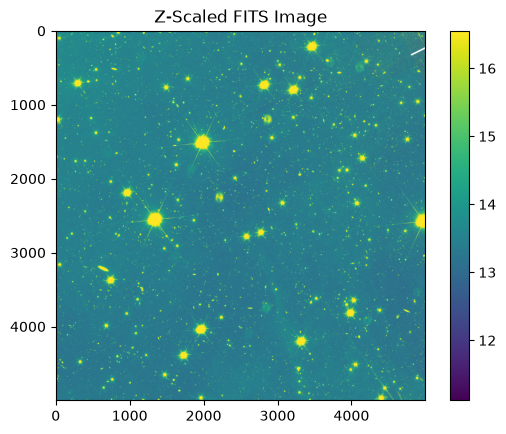

<Figure size 5000x5000 with 0 Axes>

In [4]:
# Visualize the array
fig, ax = plt.subplots()
im = ax.imshow(image_data, vmin=vmin, vmax=vmax, origin='upper')
ax.set_title("Z-Scaled FITS Image")
plt.colorbar(im, ax=ax)
plt.figure(figsize=(50, 50))
plt.show()

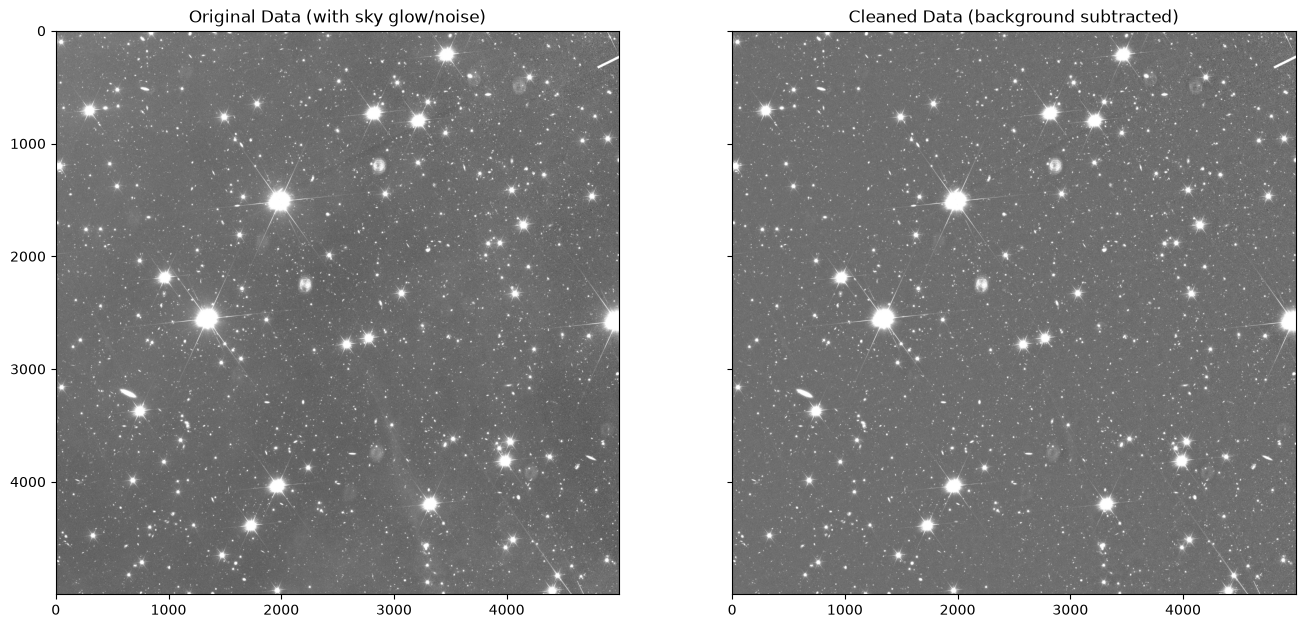

In [5]:
nan_mask = ~np.isfinite(image_data)
kernel = Gaussian2DKernel(x_stddev=2.0)

def source_mask(data, n_sigma, dilate_iter):
    d = np.where(nan_mask, 0.0, data)
    thr = detect_threshold(d, n_sigma=n_sigma, mask=nan_mask)
    segm = detect_sources(convolve(d, kernel), thr, n_pixels=5)
    if segm is None:
        return nan_mask.copy()
    m = binary_dilation(segm.data > 0, iterations=dilate_iter)
    return m | nan_mask

def fit_bkg(data, mask, box=48, filt=3):
    return Background2D(
        data, box_size=(box, box), filter_size=(filt, filt),
        sigma_clip=SigmaClip(sigma=3.0, maxiters=10),
        bkg_estimator=MedianBackground(),
        mask=mask, exclude_percentile=40)

# pass 1: rough mask from raw data
mask1 = source_mask(image_data, n_sigma=3.0, dilate_iter=6)
bkg1 = fit_bkg(image_data, mask1)
clean1 = image_data - bkg1.background

# pass 2: better mask from the flattened image, lower threshold
mask2 = source_mask(clean1, n_sigma=1.5, dilate_iter=8)
bkg2 = fit_bkg(image_data, mask2)
clean_data = image_data - bkg2.background

norm = ImageNormalize(clean_data, interval=ZScaleInterval(), stretch=LinearStretch())

# Visualize the Before and After
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
ax1.imshow(image_data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax) #0, 1000
ax1.set_title('Original Data (with sky glow/noise)')

ax2.imshow(clean_data, origin='upper', cmap='gray', norm=norm)
ax2.set_title('Cleaned Data (background subtracted)')
plt.show()

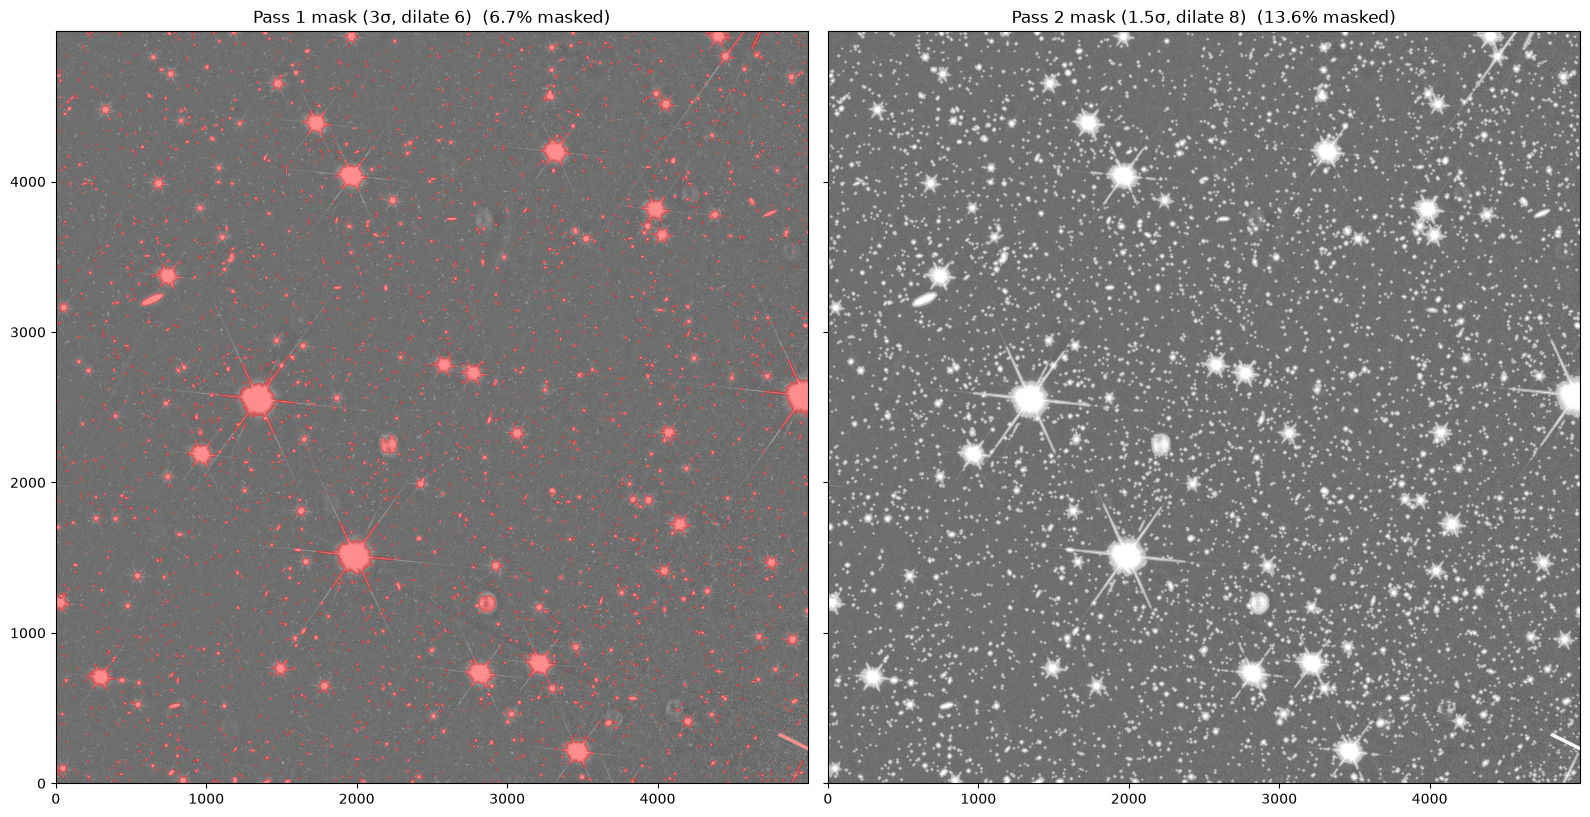

In [6]:
norm = ImageNormalize(clean1, interval=ZScaleInterval(), stretch=LinearStretch())

def overlay(ax, img, mask, title, color='red', alpha=0.45):
    ax.imshow(img, origin='lower', cmap='gray', norm=norm)
    ov = np.ma.masked_where(~mask, np.ones(mask.shape))
    ax.imshow(ov, origin='lower', cmap=plt.matplotlib.colors.ListedColormap([color]),
              alpha=alpha, vmin=0, vmax=1)
    ax.set_title(f"{title}  ({mask.mean()*100:.1f}% masked)")

# full field: pass 1 vs pass 2
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
overlay(axes[0], clean1, mask1, 'Pass 1 mask (3σ, dilate 6)')
overlay(axes[1], clean1, mask2, 'Pass 2 mask (1.5σ, dilate 8)', color='white')
plt.tight_layout(); 
plt.show()

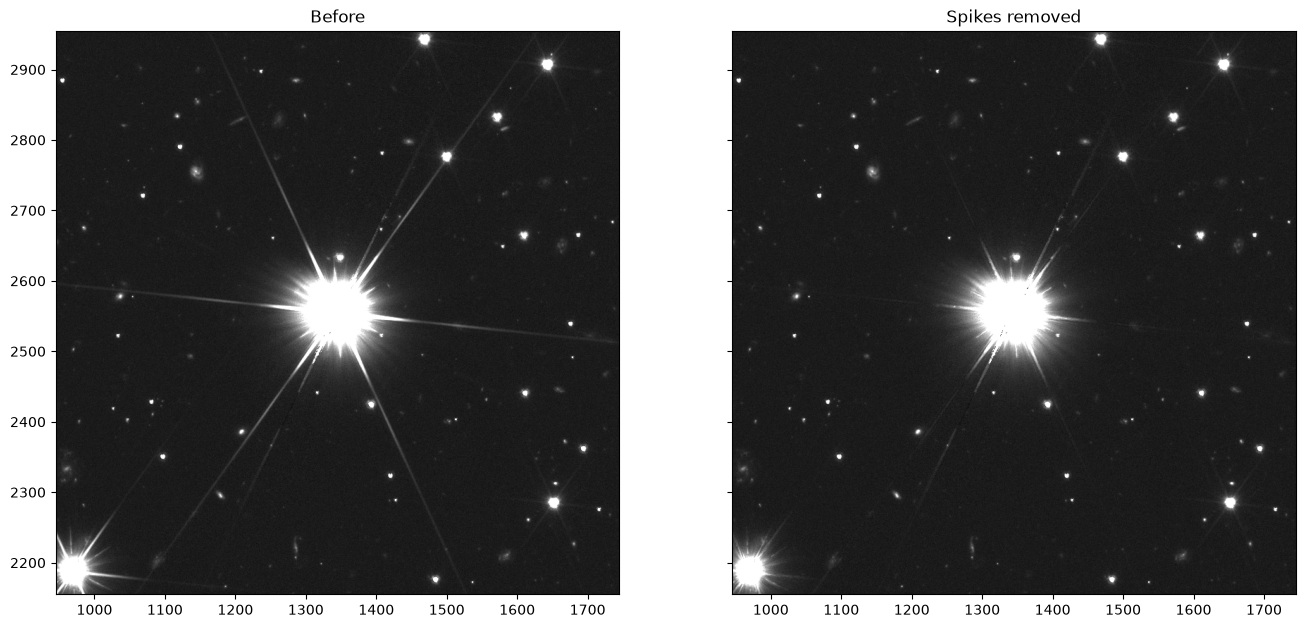

In [ ]:
# remove the six-pointed diffraction spikes around bright stars
from scipy.ndimage import map_coordinates, percentile_filter, label, center_of_mass
from scipy.ndimage import map_coordinates, percentile_filter, label, center_of_mass, gaussian_filter1d

ARMS = np.concatenate([54.5 + 60*np.arange(6), 34.0 + 60*np.arange(6)]) % 360
def spike_model(img, cy, cx, R, arms=ARMS, core_px=5.0, flank_px=10.0, dth=0.25, r_min=12):
    """Polar spike model: per arm, (pixels within core_px of the arm axis) minus (local flank level)."""
    th = np.deg2rad(np.arange(0, 360, dth)); r = np.arange(0, R, 1.0)
    T, Rr = np.meshgrid(th, r, indexing='ij')
    pol = map_coordinates(img, [cy + Rr*np.sin(T), cx + Rr*np.cos(T)], order=1, mode='constant', cval=np.nan)
    deg = np.rad2deg(th); model = np.zeros_like(pol)
    for arm in arms:
        dlt = np.deg2rad((deg - arm + 180) % 360 - 180)
        perp = np.abs(r[None, :] * np.sin(dlt)[:, None]); near = np.abs(dlt)[:, None] < np.pi/2
        wedge = near & (perp <= core_px); flank = near & (perp > core_px) & (perp <= flank_px)
        sel = np.where(np.abs(dlt) < np.deg2rad(25))[0]
        for j in range(r_min, R):
            f = pol[sel][flank[sel, j], j]; f = f[np.isfinite(f)]
            if f.size < 2: continue
            w = wedge[sel, j]
            model[sel[w], j] = pol[sel[w], j] - np.median(f)
    model = np.nan_to_num(model)
    # percentile along r drops compact sources lying in the arm but keeps radially-long spikes
    model = np.maximum(percentile_filter(model, 40, size=(1, 41), mode="nearest"), 0)
    return model, th, r

def subtract_spikes(img, peak_thr=3000, **kw):
    out = img.copy(); H, W = img.shape
    lab, n = label(np.nan_to_num(img) > peak_thr)
    yy, xx = np.mgrid[0:H, 0:W]
    for i in range(1, n+1):
        m = lab == i
        if m.sum() < 15: continue
        cy, cx = center_of_mass(np.where(m, img, 0))
        pk = np.nanmax(img[m]); R = 450 if pk > 15000 else 250
        ex, th, r = spike_model(img, cy, cx, R, **kw)
        y0, y1 = int(max(cy-R, 0)), int(min(cy+R+1, H)); x0, x1 = int(max(cx-R, 0)), int(min(cx+R+1, W))
        dy = yy[y0:y1, x0:x1]-cy; dx = xx[y0:y1, x0:x1]-cx
        rr = np.hypot(dx, dy); tt = np.mod(np.arctan2(dy, dx), 2*np.pi)
        mod = map_coordinates(ex, [tt/np.deg2rad(0.25), rr], order=1, mode='constant', cval=0)
        out[y0:y1, x0:x1] -= mod
    return out


In [9]:
# remove the six-pointed diffraction spikes around bright stars
# (objects sitting on a spike are protected: the spike underneath them is interpolated, not subtracted)
from scipy.ndimage import map_coordinates, percentile_filter, median_filter, binary_dilation, label, center_of_mass
from scipy.ndimage import map_coordinates, percentile_filter, median_filter, binary_dilation, label, center_of_mass, gaussian_filter1d

ARMS = np.concatenate([54.5 + 60*np.arange(6), 34.0 + 60*np.arange(6)]) % 360
def spike_model(img, cy, cx, R, objmask, arms=ARMS, core_px=5.0, flank_px=10.0, dth=0.25, r_min=12):
    """Polar spike model: per arm, (pixels within core_px of the arm axis) minus (local flank level)."""
    th = np.deg2rad(np.arange(0, 360, dth)); r = np.arange(0, R, 1.0)
    T, Rr = np.meshgrid(th, r, indexing='ij')
    pol = map_coordinates(img, [cy + Rr*np.sin(T), cx + Rr*np.cos(T)], order=1, mode='constant', cval=np.nan)
    deg = np.rad2deg(th); model = np.zeros_like(pol)
    om = map_coordinates(objmask.astype(float), [cy + Rr*np.sin(T), cx + Rr*np.cos(T)], order=0, mode='constant', cval=0) > 0.5
    for arm in arms:
        dlt = np.deg2rad((deg - arm + 180) % 360 - 180)
        perp = np.abs(r[None, :] * np.sin(dlt)[:, None]); near = np.abs(dlt)[:, None] < np.pi/2
        wedge = near & (perp <= core_px); flank = near & (perp > core_px) & (perp <= flank_px)
        sel = np.where(np.abs(dlt) < np.deg2rad(25))[0]
        for j in range(r_min, R):
            f = pol[sel][flank[sel, j], j]; f = f[np.isfinite(f)]
            if f.size < 2: continue
            w = wedge[sel, j]
            model[sel[w], j] = pol[sel[w], j] - np.median(f)
    model[om] = np.nan    # objects on the arm: interpolate the spike underneath instead of subtracting them
    for k in np.where(np.isnan(model).any(axis=1))[0]:
        g = np.isfinite(model[k])
        model[k] = np.interp(r, r[g], model[k, g]) if g.sum() > 5 else 0.0
    model = np.nan_to_num(model)
    # percentile along r drops compact sources lying in the arm but keeps radially-long spikes
    model = np.maximum(percentile_filter(model, 40, size=(1, 101), mode="nearest"), 0)
    return model, th, r

def object_mask(img, sigma=0.47, n_sigma=4.0, size=9):
    """Compact blobs (stars, galaxies, anything wider than the ~3 px spikes) via a 2D median high-pass."""
    f = np.nan_to_num(img)
    return binary_dilation((f - median_filter(f, size=size)) > n_sigma*sigma, iterations=2)

def subtract_spikes(img, peak_thr=3000, **kw):
    out = img.copy(); H, W = img.shape
    objmask = object_mask(img)
    lab, n = label(np.nan_to_num(img) > peak_thr)
    yy, xx = np.mgrid[0:H, 0:W]
    for i in range(1, n+1):
        m = lab == i
        if m.sum() < 15: continue
        cy, cx = center_of_mass(np.where(m, img, 0))
        pk = np.nanmax(img[m]); R = 450 if pk > 15000 else 250
        ex, th, r = spike_model(img, cy, cx, R, objmask, **kw)
        y0, y1 = int(max(cy-R, 0)), int(min(cy+R+1, H)); x0, x1 = int(max(cx-R, 0)), int(min(cx+R+1, W))
        dy = yy[y0:y1, x0:x1]-cy; dx = xx[y0:y1, x0:x1]-cx
        rr = np.hypot(dx, dy); tt = np.mod(np.arctan2(dy, dx), 2*np.pi)
        mod = map_coordinates(ex, [tt/np.deg2rad(0.25), rr], order=1, mode='constant', cval=0)
        out[y0:y1, x0:x1] -= mod
    return out

despiked = subtract_spikes(clean_data)


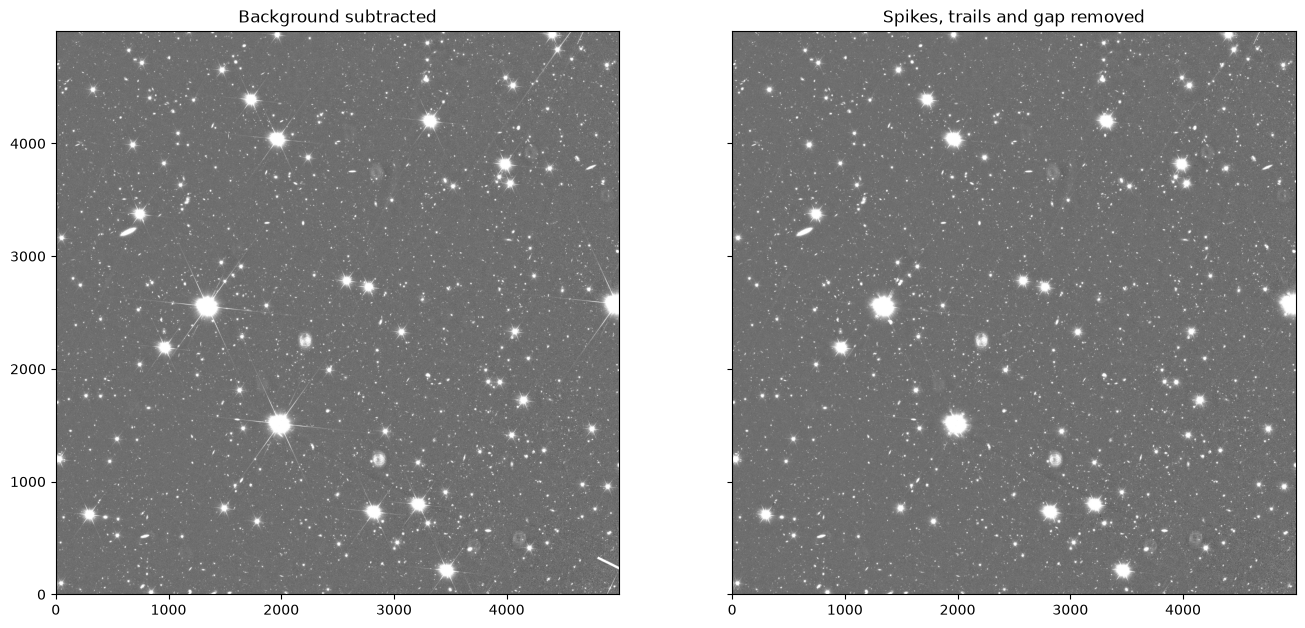

In [10]:
# remove long straight trails (satellites / meteors) and fill the missing-data gap
from scipy.ndimage import gaussian_filter, binary_opening
from skimage.measure import regionprops
from scipy.ndimage import gaussian_filter, binary_opening
from skimage.measure import regionprops
from scipy.ndimage import label, binary_dilation
SIG=0.47
def _disk(r):
    y, x = np.ogrid[-r:r+1, -r:r+1]; return x*x + y*y <= r*r

def streak_mask(img, thrs=(3.5, 8.0, 20.0, 35.0, 50.0), min_len=60, max_aspect=0.1, dilate=5):
    """Long, thin, straight features (satellite/meteor trails and their dark twins), found after removing blobs.
    Several thresholds, so bright trails (whose wings look wide at low threshold) are caught by their thin cores."""
    f = np.nan_to_num(img); sm = gaussian_filter(f, 1.5); unit = SIG/(2*np.sqrt(np.pi)*1.5)
    keep = np.zeros(f.shape, bool)
    for thr in thrs:
        for sign in (1, -1):
            b = sign*sm > thr*unit
            blobs = binary_dilation(binary_opening(b, _disk(5)), iterations=4)   # stars, galaxies, halos, noisy corners
            lab, n = label(b & ~blobs, structure=np.ones((3, 3)))
            good = [p.label for p in regionprops(lab)
                    if p.axis_major_length > min_len and p.axis_minor_length < max_aspect*p.axis_major_length + 2]
            keep |= np.isin(lab, good)
    wings = binary_dilation(keep, iterations=12) & (np.abs(sm) > 2.0*unit)    # faint wings of the bright trails
    return binary_dilation(keep, iterations=dilate) | binary_dilation(wings, iterations=2)

def inpaint(img, mask, scale=15, seed=0):
    """Fill masked pixels with the local unmasked mean plus noise matched to the local scatter."""
    f = np.nan_to_num(img); w = (~mask).astype(float)
    g = lambda a: gaussian_filter(a, scale)/np.maximum(gaussian_filter(w, scale), 1e-3)
    mu = g(f*w); sd = np.sqrt(np.maximum(g(f*f*w) - mu**2, 0))
    sd = np.clip(sd, 0.3, 3*SIG)
    out = img.copy(); out[mask] = mu[mask] + np.random.default_rng(seed).normal(0, 1, mask.sum())*sd[mask]
    return out

trail_mask = streak_mask(despiked)
gap = label(~np.isfinite(despiked))[0]
sizes = np.bincount(gap.ravel()); big_gap = np.isin(gap, np.where(sizes > 100)[0]) & (gap > 0)   # skip isolated saturated pixels
final = inpaint(despiked, trail_mask | big_gap)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
norm = ImageNormalize(clean_data, interval=ZScaleInterval(), stretch=LinearStretch())   # same stretch as the earlier plots
ax1.imshow(clean_data, origin='lower', cmap='gray', norm=norm); ax1.set_title('Background subtracted')
ax2.imshow(final, origin='lower', cmap='gray', norm=norm); ax2.set_title('Spikes, trails and gap removed')
plt.show()


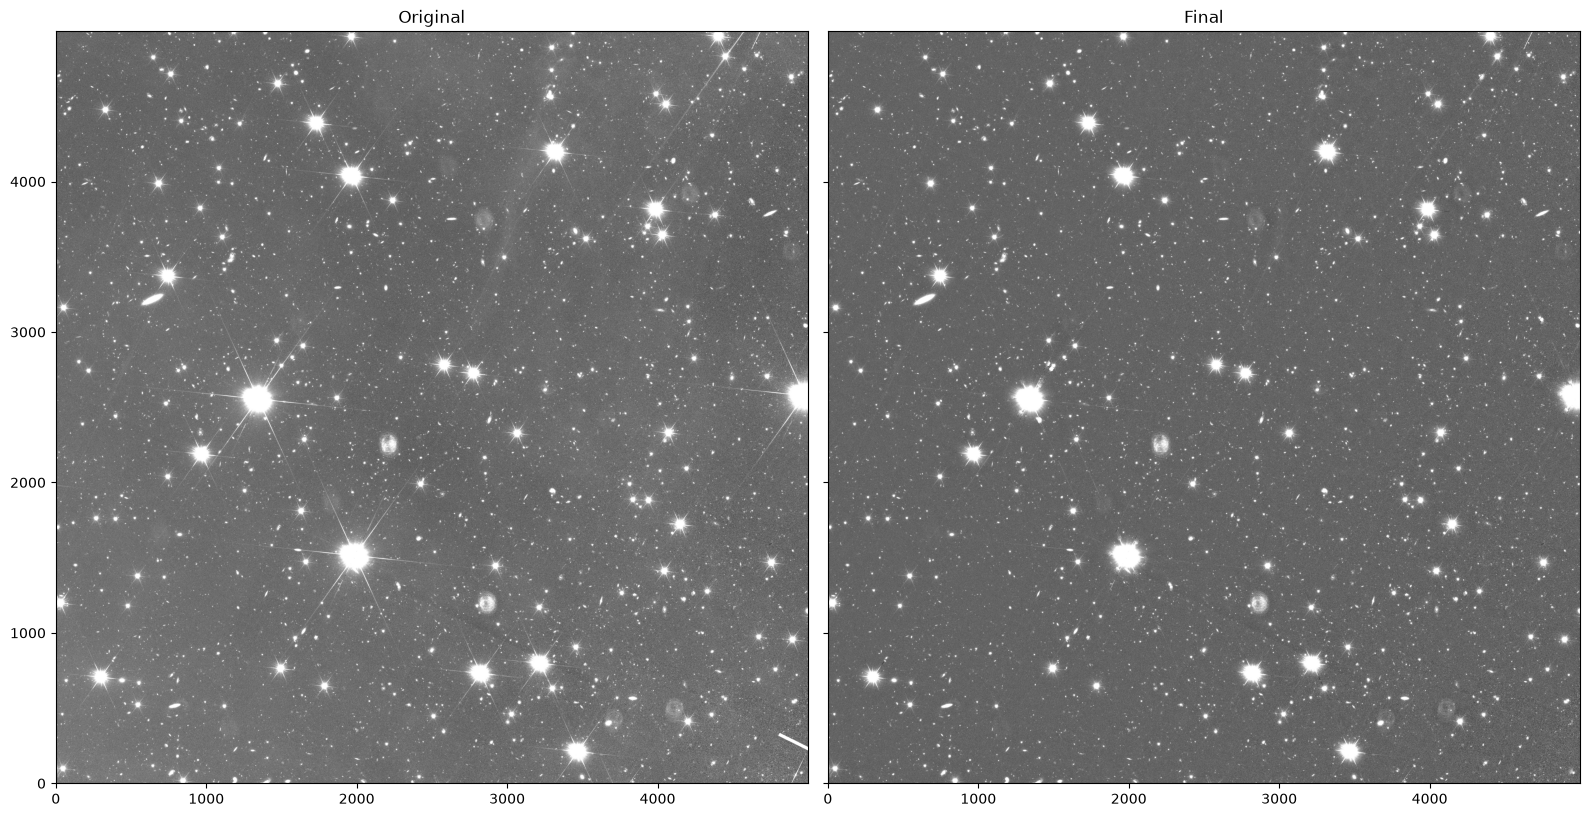

In [12]:
# save the finished image
fits.writeto('ERO_nonDGL_subregion_final.fits', final.astype('float32'), header=hdul[0].header, overwrite=True)

norm = ImageNormalize(final, interval=ZScaleInterval(), stretch=LinearStretch())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
ax1.imshow(image_data, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
ax1.set_title('Original')
ax2.imshow(final, origin='lower', cmap='gray', norm=norm)
ax2.set_title('Final')
plt.tight_layout()
plt.show()